# 📘 Building a Knowledge Graph from Wikipedia Structured Data

In this notebook, I have construct a basic knowledge graph using the [Wikipedia Structured Contents dataset](https://www.kaggle.com/datasets/wikimedia-foundation/wikipedia-structured-contents/data) available on Kaggle.


## 🗃️ Setup and File Exploration

In [1]:
import numpy as np
import pandas as pd
import json
import os
import networkx as nx
import matplotlib.pyplot as plt
from tqdm import tqdm


In [2]:
# List all files in the input directory and store them
input_files = []

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        full_path = os.path.join(dirname, filename)
        input_files.append(full_path)

# Preview the first few files
input_files[:5]


['/kaggle/input/wikipedia-structured-contents/enwiki/schema.json',
 '/kaggle/input/wikipedia-structured-contents/enwiki/data/enwiki_namespace_0_00000.parquet',
 '/kaggle/input/wikipedia-structured-contents/enwiki/data/enwiki_namespace_0_00001.parquet',
 '/kaggle/input/wikipedia-structured-contents/enwiki/data/enwiki_namespace_0_00002.parquet',
 '/kaggle/input/wikipedia-structured-contents/enwiki/data/enwiki_namespace_0_00003.parquet']

## 📂 Load a Sample Wikipedia JSON File

In [3]:
import pyarrow.dataset as ds
import pandas as pd
# Point to your dataset directory
dataset = ds.dataset("/kaggle/input/wikipedia-structured-contents/enwiki/data/", format="parquet")

# Grab only the first scanner batch (keeps memory usage tiny!)
scanner = dataset.scanner(columns=["name", "abstract", "infoboxes", "url"], batch_size=50)
table = scanner.head(20)  # Only take the first 20 rows
df = table.to_pandas()

print(f"✅ Safely loaded {len(df)} articles without crashing!")
display(df.head(5))


✅ Safely loaded 20 articles without crashing!


,name,abstract,infoboxes,url
0,"""Khan gizi"" spring","""Khan gizi"" spring is a spring located next to...","[{""type"":""infobox"",""name"":""Infobox historic si...",https://en.wikipedia.org/wiki/%22Khan_gizi%22_...
1,1113 in Italy,Events during the year 1113 in Italy.,"[{""type"":""infobox"",""name"":""Year in Italy"",""has...",https://en.wikipedia.org/wiki/1113_in_Italy
2,18th Infantry Division (France),The 18th Infantry Division was a French Army f...,None,https://en.wikipedia.org/wiki/18th_Infantry_Di...
3,1933 Greek parliamentary election,Parliamentary elections were held in Greece on...,"[{""type"":""infobox"",""name"":""Infobox election"",""...",https://en.wikipedia.org/wiki/1933_Greek_parli...
4,1903 German football championship,The 1903 German football championship was the ...,"[{""type"":""infobox"",""name"":""Infobox football to...",https://en.wikipedia.org/wiki/1903_German_foot...


In [4]:
import spacy

nlp = spacy.load("en_core_web_sm")

# Get the actual number of rows in your dataframe
num_rows = len(df)
print(f"Total rows in dataframe: {num_rows}")

# Loop safely up to 3 rows (or fewer if the dataframe is smaller)
for i in range(min(3, num_rows)):
    text = df['abstract'].iloc[i]
    print(f"\n--- Article {i+1} ---")
    
    if pd.isna(text) or not str(text).strip():
        print(" -> Skipping: Text is empty or NaN.")
        continue
        
    doc = nlp(str(text))
    print(f" -> Entities found: {len(doc.ents)}")
    for ent in doc.ents[:3]:
        print(f"    - {ent.text} ({ent.label_})")

Total rows in dataframe: 20

--- Article 1 ---
 -> Entities found: 20
    - Khan (PERSON)
    - a spring (DATE)
    - Khan (PERSON)

--- Article 2 ---
 -> Entities found: 2
    - the year 1113 (DATE)
    - Italy (GPE)

--- Article 3 ---
 -> Entities found: 5
    - 18th (ORDINAL)
    - Infantry Division (ORG)
    - French Army (ORG)


## 🧠 Extract Entities and Relations from the Infobox

In [5]:
import json

def extract_entity_relations(article):
    title = article.get("name", "Unknown Entity")
    relations = []
    
    infoboxes = article.get("infoboxes", [])
    
    # Safely decode if infoboxes is a JSON string
    if isinstance(infoboxes, str):
        try: infoboxes = json.loads(infoboxes)
        except: infoboxes = []
    
    if not isinstance(infoboxes, list):
        infoboxes = []

    for infobox in infoboxes:
        if isinstance(infobox, str):
            try: infobox = json.loads(infobox)
            except: continue
        if not isinstance(infobox, dict):
            continue
            
        if infobox.get("type") != "infobox":
            continue
            
        for section in infobox.get("has_parts", []):
            if isinstance(section, str):
                try: section = json.loads(section)
                except: continue
            if not isinstance(section, dict):
                continue
                
            section_name = section.get("name", "")
            for part in section.get("has_parts", []):
                if isinstance(part, str):
                    try: part = json.loads(part)
                    except: continue
                if not isinstance(part, dict):
                    continue
                    
                if part.get("type") == "field":
                    predicate = part.get("name", section_name) or section_name
                    obj = part.get("value")
                    if obj:
                        relations.append((title, predicate, obj))
                        
    return relations

In [6]:
# Diagnostic scan across all loaded rows
for idx, row in df.iterrows():
    article = row.to_dict()
    title = article.get("name", "Unknown")
    infoboxes = article.get("infoboxes", [])
    
    print(f"Row {idx}: '{title}' -> Infoboxes raw type: {type(infoboxes)}, length: {len(infoboxes) if hasattr(infoboxes, '__len__') else 'N/A'}")
    
    # Try extracting triplets and show count if any
    triplets = extract_entity_relations(article)
    if triplets:
        print(f"   🎉 SUCCESS! Found {len(triplets)} triplets!")
        print(triplets[:3])
        break
else:
    print("\n⚠️ Checked all rows, but none matched the current infobox schema path.")

Row 0: '"Khan gizi" spring' -> Infoboxes raw type: <class 'str'>, length: 1360
   🎉 SUCCESS! Found 5 triplets!
[('"Khan gizi" spring', 'Type', 'spring'), ('"Khan gizi" spring', 'Location', 'Shusha, Azerbaijan'), ('"Khan gizi" spring', 'Coordinates', '39°45′51″N 46°45′04″E / 39.7642°N 46.7510°E')]


## 🔄 Extract Relations from Multiple Articles

In [7]:
all_triplets = []

# Loop through your loaded dataframe records safely
for article in tqdm(df.to_dict(orient='records')):
    all_triplets.extend(extract_entity_relations(article))

# Build your final triplet DataFrame
triplet_df = pd.DataFrame(all_triplets, columns=["Entity", "Relation", "Value"])
triplet_df.head(10)

100%|██████████| 20/20 [00:00<00:00, 28397.45it/s]


,Entity,Relation,Value
0,"""Khan gizi"" spring",Type,spring
1,"""Khan gizi"" spring",Location,"Shusha, Azerbaijan"
2,"""Khan gizi"" spring",Coordinates,39°45′51″N 46°45′04″E / 39.7642°N 46.7510°E
3,"""Khan gizi"" spring",Founded,1871
4,"""Khan gizi"" spring",Founder,Khurshidbanu Natavan
5,1113 in Italy,,← 1113 in Italy →
6,1113 in Italy,Decades,Decades
7,1933 Greek parliamentary election,5 March 1933,5 March 1933
8,1933 Greek parliamentary election,All 248 seats in the Vouli 125 seats needed fo...,First party Second party Third party Leader Pa...
9,1933 Greek parliamentary election,All 248 seats in the Vouli 125 seats needed fo...,First party Second party Third party


## 🌐 Build and Visualize the Knowledge Graph

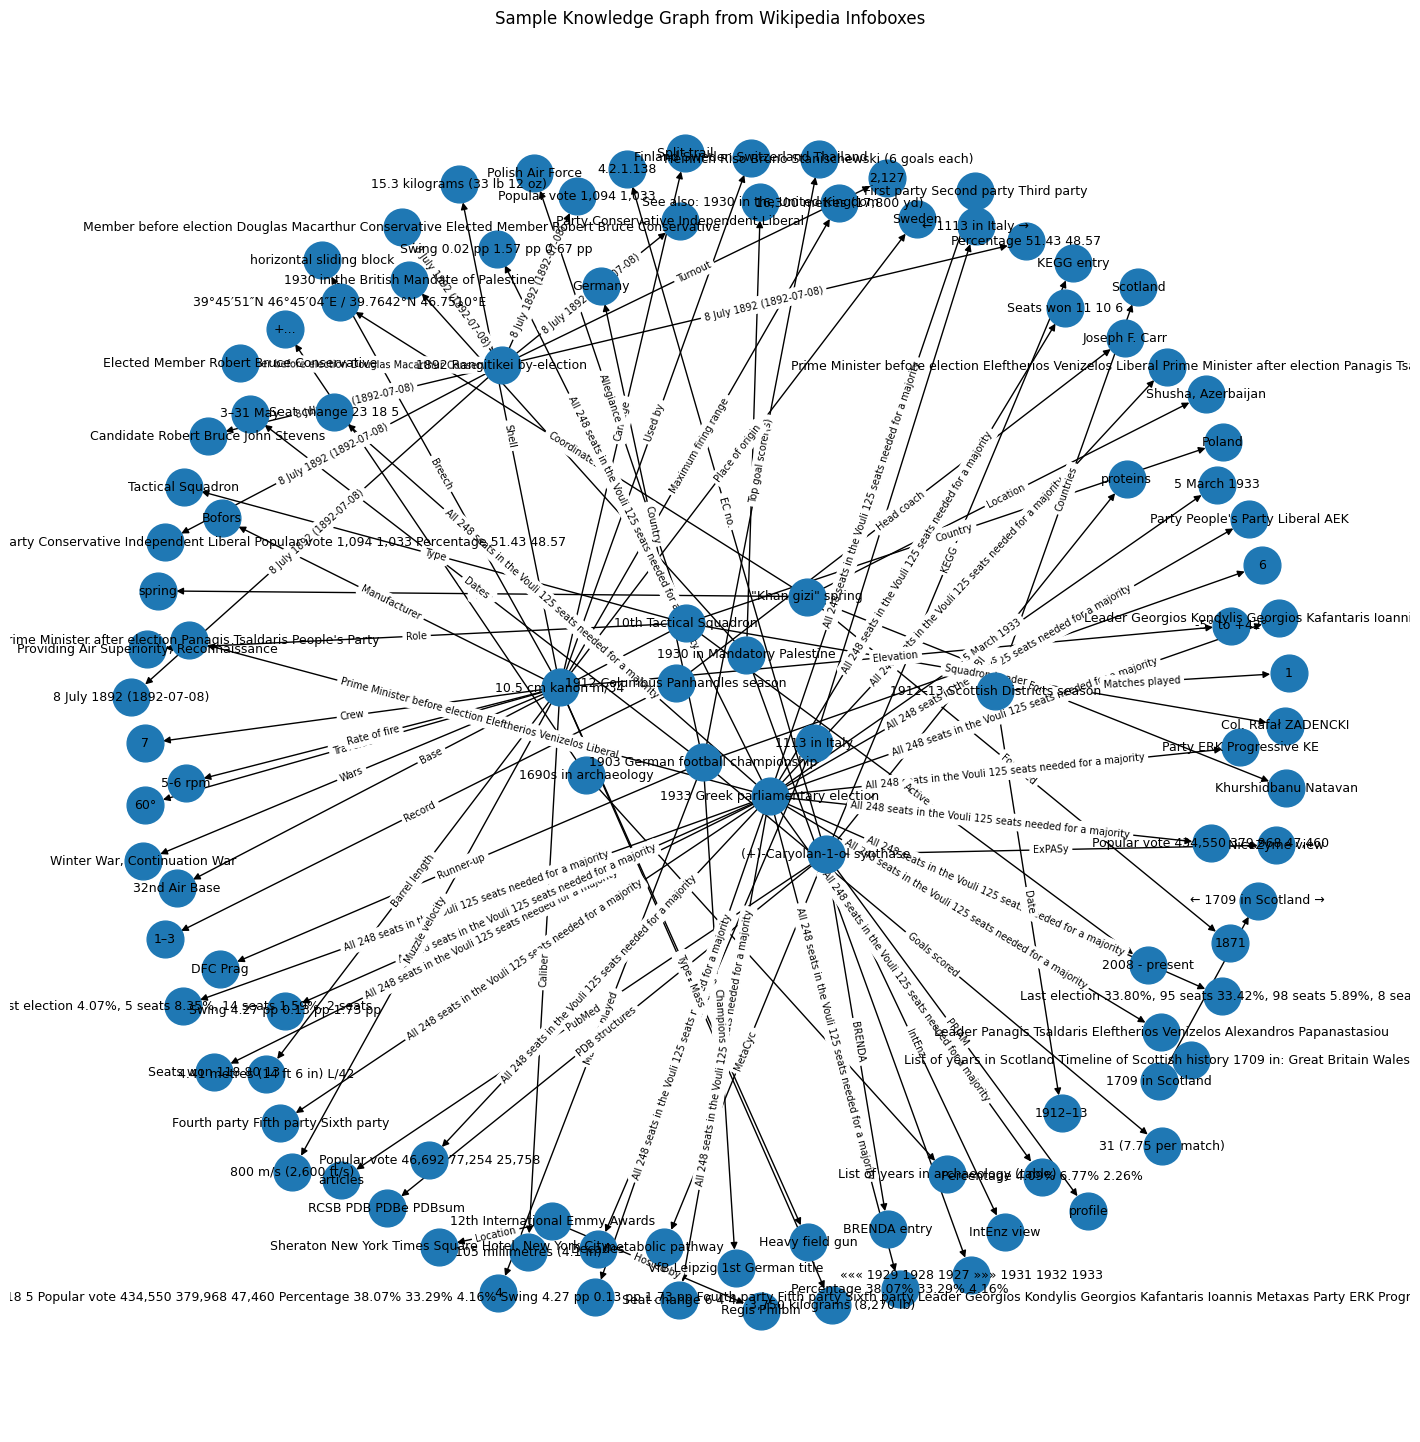

In [8]:
G = nx.DiGraph()

# Add limited number of edges for clarity
for subj, rel, obj in all_triplets[:100]:
    G.add_edge(subj, obj, label=rel)

plt.figure(figsize=(14, 14))
pos = nx.spring_layout(G, k=0.5)
edge_labels = nx.get_edge_attributes(G, 'label')

nx.draw(G, pos, with_labels=True, node_size=700, font_size=9, arrowsize=10)
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)
plt.title("Sample Knowledge Graph from Wikipedia Infoboxes")
plt.show()
